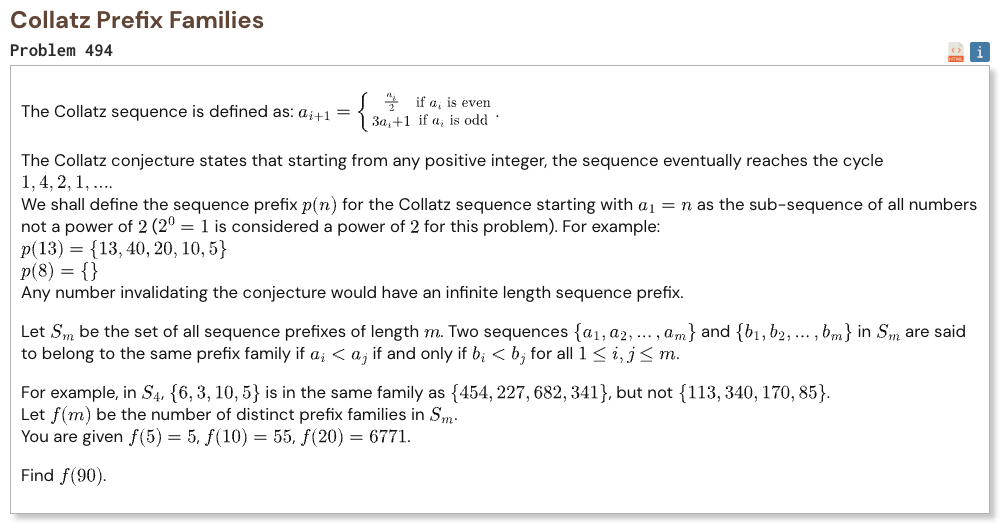

## Initial approach

- start with the main family count, which follows the Fibonacci sequence
- this works because the valid reverse Collatz choices cannot branch freely at every step
- a small set of exceptional starting values creates additional prefix families
- for each exceptional value, follow its Collatz path until it reaches a power of two
- then work backwards for the remaining number of steps and count every valid predecessor
- every value always has one even predecessor and sometimes has one extra odd predecessor
- if a value is divisible by three, its backward path can no longer branch
- add all exceptional family counts to the main Fibonacci count

In [1]:
%%time

def fibonacci(n):
    if n <= 0:
        return 0

    if n <= 2:
        return 1

    a = 1
    b = 1

    for _ in range(n - 2):
        a, b = b, a + b

    return b


def collatz_length(n):
    length = 0

    while n & (n - 1):
        length += 1

        if n % 2 == 0:
            n //= 2
        else:
            n = 3 * n + 1

    return length


def count_back(start, steps):
    if steps < 0:
        return 0

    if start % 3 == 0:
        return 1

    states = [start]

    for _ in range(steps):
        next_states = []

        for x in states:
            next_states.append(2 * x)

            if x % 6 == 4:
                next_states.append((x - 1) // 3)

        states = next_states

    return len(states)


m = 90
seeds = [9, 19, 37, 51, 155, 159]

result = fibonacci(m)

for seed in seeds:
    remaining = m - collatz_length(seed)
    result += count_back(seed, remaining)

print("Result:", result)

Result: 2880067194446832666
CPU times: user 20.5 s, sys: 3.12 s, total: 23.6 s
Wall time: 24.1 s
